# Backtesting One-Day VaR on the S&P 500
## Rolling empirical distribution versus normal log returns with EWMA updating

A portfolio keeps a constant \$1 in the S&P 500 index. Each trading day, using only
information available at that day's close, the notebook forecasts the 95% VaR of the
next day's loss in two ways — from the **empirical distribution** of the last
$M=1010$ log returns (about four years), and from a **normal model** whose mean and
variance are updated by EWMA — and records an **exceedance** whenever the realised
loss is larger than the forecast. The number of exceedances over the
$J$ evaluation days is then compared with its 95% confidence interval under the
hypothesis that the model is correct.

**Loss.** With a constant \$1 position the full loss operator is
$\ell(x)=-(e^{x}-1)$, $x$ the next day's log return.

**The two forecasts** made at day $t$ for $[t,t+\Delta]$:

$$\widehat{\mathrm{VaR}}{}^{\,\mathrm{emp}}_t=\ell_{(\lceil M\alpha\rceil)}\ \text{ of }\ \{\ell(x_{t-(m-1)\Delta})\}_{m=1}^{M},
\qquad
\widehat{\mathrm{VaR}}{}^{\,\mathrm{EWMA}}_t=1-e^{\hat\mu_{t+\Delta}+\hat\sigma_{t+\Delta}\Phi^{-1}(1-\alpha)},$$

$$\hat\mu_{t+\Delta}=\lambda\hat\mu_t+(1-\lambda)x_t,\qquad
\hat\sigma^2_{t+\Delta}=\theta\hat\sigma^2_t+(1-\theta)(x_t-\hat\mu_t)^2 .$$

**The test.** If the model is right the exceedance indicators are i.i.d.
Bernoulli$(1-\alpha)$, so the count $N^J$ is Binomial$(J,1-\alpha)$ and, for large
$J$, lies in $\bigl[J(1-\alpha)\mp z_{1-\beta/2}\sqrt{J\alpha(1-\alpha)}\bigr]$
with probability about $1-\beta$.

---
## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm, binom, skew, kurtosis
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.16
numpy       2.5.3
pandas      3.0.5
scipy       1.18.1
matplotlib  3.11.2


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| — | index (Yahoo Finance ticker) | S&P 500 (`^GSPC`) |
| — | sample period (closing prices) | 05/23/2016 – 05/22/2026 |
| $\alpha$ | VaR confidence level | 0.95 |
| $\beta$ | test level, so the interval has confidence $1-\beta$ | 0.05 |
| $M$ | rolling window, log returns (about four years) | 1010 |
| $\lambda,\ \theta$ | EWMA decay for mean and variance | 0.97, 0.97 |

In [2]:
TICKER    = "^GSPC"
FIRST_DAY = "2016-05-23"
LAST_DAY  = "2026-05-22"
ALPHA, BETA = 0.95, 0.05
M_WIN     = 1010
LAM = THETA = 0.97

DATA_FILE = Path("sp500_prices.csv")
FIG1 = Path("backtest_var_paths.png")
FIG2 = Path("backtest_cumulative_exceedances.png")

C_EMP, C_EW = "#2a78d6", "#eb6834"
C_INK, C_MUTE = "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
loss = lambda x: -np.expm1(x)          # full loss operator, $1 position
print(f"alpha = {ALPHA}, beta = {BETA}, M = {M_WIN}, lambda = theta = {LAM}")

alpha = 0.95, beta = 0.05, M = 1010, lambda = theta = 0.97


---
## 3. Data — Task 1

Daily closing levels of the S&P 500 index from Yahoo Finance (`auto_adjust=False`,
column `Close`; an index has no dividends or splits to adjust for). Trading days only.
Cached in `sp500_prices.csv` after the first download.

### Pseudocode — data acquisition

```
1  if the cache file exists: read it                       (no network access)
2  else: request daily raw closes of ^GSPC on [05/23/2016, 05/22/2026] from Yahoo Finance
3        ('end' is exclusive, so ask for one day past the last date); stop if nothing returns
4        sort by date; save to the cache file
5  check: first and last dates are the requested ones, no missing values, no repeated dates
```

In [3]:
def download_closes(ticker, first, last):
    """Raw daily closes from Yahoo Finance on [first, last] (only used when the cache is missing)."""
    import yfinance as yf
    end = (pd.Timestamp(last) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    df = yf.download(ticker, start=first, end=end, interval="1d", auto_adjust=False,
                     actions=False, progress=False, threads=False)
    if df is None or df.empty:
        raise RuntimeError(f"Yahoo Finance returned no data for {ticker}")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    s = df["Close"].astype(float)
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    s = s.sort_index().loc[first:last].rename(ticker.lstrip("^"))
    s.index.name = "Date"
    return s.to_frame()


if DATA_FILE.exists():
    px = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)["GSPC"]
    print(f"read cached prices from {DATA_FILE}")
else:
    frame = download_closes(TICKER, FIRST_DAY, LAST_DAY)
    frame.to_csv(DATA_FILE, float_format="%.6f")
    px = frame["GSPC"]
    print(f"downloaded prices from Yahoo Finance and saved them to {DATA_FILE}")

assert str(px.index[0].date()) == FIRST_DAY and str(px.index[-1].date()) == LAST_DAY
assert px.notna().all() and not px.index.has_duplicates and px.index.is_monotonic_increasing

N = len(px)
print("\nFIRST FIVE OBSERVATIONS")
print(px.head(5).to_frame("S&P 500 close").to_string(float_format=lambda v: f"{v:12.2f}"))
print("\nLAST FIVE OBSERVATIONS")
print(px.tail(5).to_frame("S&P 500 close").to_string(float_format=lambda v: f"{v:12.2f}"))
print(f"\ntotal number of observations  N = {N:,} daily closes ({px.index[0].date()} to {px.index[-1].date()})")

read cached prices from sp500_prices.csv

FIRST FIVE OBSERVATIONS
            S&P 500 close
Date                     
2016-05-23        2048.04
2016-05-24        2076.06
2016-05-25        2090.54
2016-05-26        2090.10
2016-05-27        2099.06

LAST FIVE OBSERVATIONS
            S&P 500 close
Date                     
2026-05-18        7403.05
2026-05-19        7353.61
2026-05-20        7432.97
2026-05-21        7445.72
2026-05-22        7473.47

total number of observations  N = 2,515 daily closes (2016-05-23 to 2026-05-22)


---
## 4. Returns and the evaluation window

$N$ closes give $N-1$ log returns $x_k=\ln(S_k/S_{k-1})$. The first VaR forecast is
made at the close of the day of the $M$-th (1010th) return and is for the next day,
so the evaluation days are returns $M+1,\dots,N-1$:

$$J=(N-1)-M .$$

The sheet writes $J=N-M$, which counts $N$ as the number of **log returns**; with $N$
counted as closing prices, as in Task 1, the two agree once the first close (which
has no return) is set aside. Every forecast uses only returns up to and including
the forecast day, so nothing from the evaluation day leaks into its own forecast.

In [4]:
x = np.log(px).diff().dropna()
xv = x.to_numpy()
n_ret = len(xv)
J = n_ret - M_WIN
eval_dates = x.index[M_WIN:]                 # date of the return being forecast
realised = loss(xv[M_WIN:])                   # realised loss on each evaluation day

print(f"log returns: {n_ret:,}   ({x.index[0].date()} to {x.index[-1].date()})")
print(f"first estimation window: returns 1 ... {M_WIN}  ({x.index[0].date()} to {x.index[M_WIN - 1].date()})")
print(f"first evaluation day:  return {M_WIN + 1}  ({eval_dates[0].date()})")
print(f"last evaluation day:   return {n_ret}  ({eval_dates[-1].date()})")
print(f"J = (N - 1) - M = {N - 1} - {M_WIN} = {J:,} evaluation days")
assert J == len(realised) == N - 1 - M_WIN

log returns: 2,514   (2016-05-24 to 2026-05-22)
first estimation window: returns 1 ... 1010  (2016-05-24 to 2020-05-28)
first evaluation day:  return 1011  (2020-05-29)
last evaluation day:   return 2514  (2026-05-22)
J = (N - 1) - M = 2514 - 1010 = 1,504 evaluation days


---
## 5. Rolling empirical VaR — Task 2

On each evaluation day the window holds the $M=1010$ most recent returns; the VaR is
the $\lceil M\alpha\rceil=\lceil959.5\rceil=960$-th smallest of their losses (the
51st largest). An exceedance is recorded when the realised loss is **strictly**
greater than the forecast.

### Pseudocode — rolling empirical VaR and exceedances

```
INPUT : log returns x_1 ... x_n, window M, alpha
OUTPUT: VaR forecasts and exceedance indicators for days M+1 ... n

1  k* <- ceiling(M * alpha)                                   (= 960)
2  for i = M+1 ... n:                                          (the day being forecast)
3        window <- x_{i-M} ... x_{i-1}                         (the M most recent returns)
4        losses <- -(exp(window) - 1)
5        VaR_i  <- the k*-th smallest of the losses
6        realised_i <- -(exp(x_i) - 1)
7        exceed_i <- 1 if realised_i > VaR_i else 0
8  count the exceedances
```

In [5]:
K_STAR = int(np.ceil(round(M_WIN * ALPHA, 9)))
var_emp = np.empty(J)
for j in range(J):
    i = M_WIN + j                                       # 0-based index of the day being forecast
    var_emp[j] = np.sort(loss(xv[i - M_WIN:i]))[K_STAR - 1]
exc_emp = realised > var_emp
N_EMP = int(exc_emp.sum())

print(f"order statistic k* = ceil({M_WIN} x {ALPHA}) = {K_STAR}")
print(f"empirical VaR forecasts: mean {var_emp.mean():.4%}, min {var_emp.min():.4%}, max {var_emp.max():.4%}")
print(f"EXCEEDANCES (empirical method): {N_EMP} of {J:,} days  ({N_EMP / J:.2%})")

order statistic k* = ceil(1010 x 0.95) = 960
empirical VaR forecasts: mean 1.8830%, min 1.5731%, max 2.2725%
EXCEEDANCES (empirical method): 55 of 1,504 days  (3.66%)


---
## 6. Normal model with EWMA updating — Task 3

**The VaR formula.** If $X\sim N(\mu,\sigma^2)$, then $\ell(X)=1-e^{X}$ is a strictly
decreasing function of $X$, so its $\alpha$-quantile is $\ell$ evaluated at the
$(1-\alpha)$-quantile of $X$:
$\mathrm{VaR}_\alpha=1-e^{\mu+\sigma\Phi^{-1}(1-\alpha)}$ (derivation in the
handwritten part).

**Initialisation.** As the sheet allows, the first forecast (for return $M+1$) uses
the sample mean and sample variance (denominator $M-1$) of the first $M=1010$ returns:
$\hat\mu_{t+\Delta}=\bar x_{1:M}$, $\hat\sigma^2_{t+\Delta}=s^2_{1:M}$. After the
evaluation day's return $x$ is observed, the recursions update the pair for the next
day, the variance update using the mean **before** it is updated. A second
initialisation — sample moments of returns $1,\dots,M-1$ followed by one EWMA update
with $x_M$ — is run as a sensitivity check.

### Pseudocode — EWMA-normal VaR and exceedances

```
INPUT : log returns x_1 ... x_n, M, alpha, lambda, theta
OUTPUT: VaR forecasts and exceedance indicators for days M+1 ... n

1  mu  <- sample mean of x_1 ... x_M
2  var <- sample variance of x_1 ... x_M   (divide by M - 1)
3  for i = M+1 ... n:
4        VaR_i <- 1 - exp( mu + sqrt(var) * Phi^-1(1 - alpha) )   (uses information to day i-1)
5        exceed_i <- 1 if -(exp(x_i) - 1) > VaR_i else 0
6        d   <- x_i - mu                                            (OLD mean)
7        mu  <- lambda * mu  + (1 - lambda) * x_i
8        var <- theta  * var + (1 - theta)  * d^2
9  count the exceedances
```

In [6]:
Z_LO = norm.ppf(1 - ALPHA)


def ewma_backtest(mu0, var0, use_mean=True):
    """Run the EWMA-normal forecasts over the evaluation days; return VaR, mu and sigma paths."""
    mu, var = mu0, var0
    v_out, mu_out, sd_out = np.empty(J), np.empty(J), np.empty(J)
    for j in range(J):
        i = M_WIN + j
        m_ = mu if use_mean else 0.0
        v_out[j] = 1 - np.exp(m_ + np.sqrt(var) * Z_LO)
        mu_out[j], sd_out[j] = mu, np.sqrt(var)
        d = xv[i] - mu
        mu = LAM * mu + (1 - LAM) * xv[i]
        var = THETA * var + (1 - THETA) * d * d
    return v_out, mu_out, sd_out


MU_INIT, VAR_INIT = xv[:M_WIN].mean(), xv[:M_WIN].var(ddof=1)
var_ew, mu_ew, sd_ew = ewma_backtest(MU_INIT, VAR_INIT)
exc_ew = realised > var_ew
N_EW = int(exc_ew.sum())
print(f"initial estimates from returns 1 ... {M_WIN}: mu = {MU_INIT:.6e}, sigma = {np.sqrt(VAR_INIT):.6f}"
      f"  ({np.sqrt(VAR_INIT * 252):.2%} annualised)")
print(f"first EWMA forecast ({eval_dates[0].date()}): VaR = {var_ew[0]:.4%}")
print(f"EWMA VaR forecasts: mean {var_ew.mean():.4%}, min {var_ew.min():.4%}, max {var_ew.max():.4%}")
print(f"EXCEEDANCES (EWMA method): {N_EW} of {J:,} days  ({N_EW / J:.2%})")

# sensitivity: start one step earlier and let the recursion produce the first forecast
d0 = xv[M_WIN - 1] - xv[:M_WIN - 1].mean()
mu_b = LAM * xv[:M_WIN - 1].mean() + (1 - LAM) * xv[M_WIN - 1]
var_b = THETA * xv[:M_WIN - 1].var(ddof=1) + (1 - THETA) * d0 ** 2
var_ew_b, _, _ = ewma_backtest(mu_b, var_b)
N_EW_B = int((realised > var_ew_b).sum())
print(f"\nsensitivity, alternative initialisation: {N_EW_B} exceedances;"
      f" largest VaR difference {np.abs(var_ew_b - var_ew).max():.2e},"
      f" after 60 days {np.abs(var_ew_b - var_ew)[60:].max():.2e}")

initial estimates from returns 1 ... 1010: mu = 3.877131e-04, sigma = 0.012413  (19.70% annualised)
first EWMA forecast (2020-05-29): VaR = 1.9830%
EWMA VaR forecasts: mean 1.6250%, min 0.7429%, max 4.0279%
EXCEEDANCES (EWMA method): 94 of 1,504 days  (6.25%)

sensitivity, alternative initialisation: 94 exceedances; largest VaR difference 2.10e-04, after 60 days 3.93e-05


---
## 7. Confidence interval and decision — Task 4

Under the null hypothesis that the model is correct, $N^J\sim\mathrm{Bin}(J,1-\alpha)$
and, by the central limit theorem,
$\bigl(N^J-J(1-\alpha)\bigr)/\sqrt{J\alpha(1-\alpha)}\approx N(0,1)$, so

$$\tau^\beta_\pm=J(1-\alpha)\pm z_{1-\beta/2}\sqrt{J\alpha(1-\alpha)},\qquad
\mathbb P\bigl[\tau^\beta_-\le N^J\le\tau^\beta_+\bigr]\approx1-\beta .$$

A count outside the interval rejects the model at level $\beta$: too many
exceedances means the VaR is too low (the model is too optimistic), too few means it
is too high (too pessimistic). The exact binomial 2.5% and 97.5% points are printed
as a check on the normal approximation.

### Pseudocode — the test

```
1  centre <- J (1 - alpha);   half <- Phi^-1(1 - beta/2) * sqrt(J alpha (1 - alpha))
2  interval <- [centre - half, centre + half]
3  for each method: inside <- (lower <= count <= upper)
4        if count > upper: reject, VaR too low (too optimistic)
5        if count < lower: reject, VaR too high (too pessimistic)
```

In [7]:
Z_B = norm.ppf(1 - BETA / 2)
CENTRE = J * (1 - ALPHA)
HALF = Z_B * np.sqrt(J * ALPHA * (1 - ALPHA))
LO, HI = CENTRE - HALF, CENTRE + HALF
print(f"J = {J:,},  J(1-alpha) = {CENTRE:.2f},  sqrt(J alpha (1-alpha)) = {np.sqrt(J * ALPHA * (1 - ALPHA)):.4f},"
      f"  z = {Z_B:.6f}")
print(f"{1 - BETA:.0%} interval for the number of exceedances: [{LO:.2f}, {HI:.2f}]"
      f"   -> integer counts {int(np.ceil(LO))} ... {int(np.floor(HI))}")
print(f"exact binomial 2.5% and 97.5% points: {binom.ppf(BETA / 2, J, 1 - ALPHA):.0f}, "
      f"{binom.ppf(1 - BETA / 2, J, 1 - ALPHA):.0f}")


def verdict(cnt):
    if cnt > HI:
        return "outside (above): reject - VaR too low, model too optimistic"
    if cnt < LO:
        return "outside (below): reject - VaR too high, model too pessimistic"
    return "inside: do not reject"


print()
for nm, cnt in (("empirical", N_EMP), ("EWMA-normal", N_EW)):
    zsc = (cnt - CENTRE) / np.sqrt(J * ALPHA * (1 - ALPHA))
    pval = 2 * norm.sf(abs(zsc))
    print(f"  {nm:<12} {cnt:>4} exceedances   z = {zsc:+.3f}   two-sided p = {pval:.4f}   {verdict(cnt)}")

J = 1,504,  J(1-alpha) = 75.20,  sqrt(J alpha (1-alpha)) = 8.4522,  z = 1.959964
95% interval for the number of exceedances: [58.63, 91.77]   -> integer counts 59 ... 91
exact binomial 2.5% and 97.5% points: 59, 92

  empirical      55 exceedances   z = -2.390   two-sided p = 0.0169   outside (below): reject - VaR too high, model too pessimistic
  EWMA-normal    94 exceedances   z = +2.224   two-sided p = 0.0261   outside (above): reject - VaR too low, model too optimistic


---
## 8. Looking closer

The test above counts exceedances; it does not ask **when** they happen. Three
descriptive checks help interpret the two verdicts. None of them is a formal test.

* **By calendar year.** Under the null each year should show about 5% exceedances.
* **Back-to-back exceedances.** Under independence, the expected number of
  consecutive pairs is about $(J-1)p^2$ with $p$ the observed rate.
* **The EWMA mean.** With $\lambda=0.97$ the mean estimate has an effective memory of
  about 33 days and moves a lot. Re-running the EWMA method with $\hat\mu\equiv0$
  (variance unchanged) shows how much of its result is due to the mean.
* **The normal shape.** If the model were right, the standardised returns
  $(x-\hat\mu)/\hat\sigma$ would be standard normal; their skewness, kurtosis and 5%
  quantile show whether the left tail is heavier than the normal model allows.

In [8]:
by_year = pd.DataFrame({"days": 1, "empirical": exc_emp.astype(int), "EWMA": exc_ew.astype(int)},
                       index=eval_dates).groupby(eval_dates.year).sum()
by_year["expected (5%)"] = (by_year["days"] * (1 - ALPHA)).round(1)
by_year.index.name = "year"
print("EXCEEDANCES BY YEAR")
print(by_year.to_string())

print("\nBACK-TO-BACK EXCEEDANCES")
for nm, e in (("empirical", exc_emp), ("EWMA", exc_ew)):
    p = e.mean()
    print(f"  {nm:<10} observed {int((e[1:] & e[:-1]).sum()):>3}    expected under independence {(J - 1) * p * p:5.1f}")

var_ew0, _, _ = ewma_backtest(MU_INIT, VAR_INIT, use_mean=False)
N_EW0 = int((realised > var_ew0).sum())
print(f"\nEWMA with the mean set to zero: {N_EW0} exceedances  -> {verdict(N_EW0)}")
print(f"EWMA mean estimate over the evaluation period: from {mu_ew.min():+.3%} to {mu_ew.max():+.3%} per day"
      f" (sample mean of all returns {xv.mean():+.3%})")
print(f"share of days on which the EWMA mean term lowered the VaR (mu > 0): {(mu_ew > 0).mean():.1%}")

# how normal are the returns once standardised by the EWMA forecasts?
z_res = (xv[M_WIN:] - mu_ew) / sd_ew
print(f"\nstandardised returns (x - mu_hat) / sigma_hat on the evaluation days:")
print(f"  sd {z_res.std(ddof=1):.3f}   skewness {skew(z_res):+.3f}   excess kurtosis {kurtosis(z_res):.3f}")
print(f"  5% quantile {np.quantile(z_res, 1 - ALPHA):+.3f}   (normal: {Z_LO:+.3f});"
      f"  share below {Z_LO:.3f}: {(z_res < Z_LO).mean():.2%}")

# window content: the COVID crash stays in the empirical window until it rolls out
covid = (x.index >= "2020-02-20") & (x.index <= "2020-04-30")
covid_idx = np.flatnonzero(covid)
out_day = x.index[covid_idx.max() + M_WIN].date()
print(f"\nthe Feb-Apr 2020 returns stay inside the empirical window until {out_day}")

EXCEEDANCES BY YEAR
      days  empirical  EWMA  expected (5%)
year                                      
2020   151          8     7            7.6
2021   252          6    12           12.6
2022   251         20    19           12.6
2023   250          0    13           12.5
2024   252          7    18           12.6
2025   250         11    15           12.5
2026    98          3    10            4.9

BACK-TO-BACK EXCEEDANCES
  empirical  observed   5    expected under independence   2.0
  EWMA       observed   6    expected under independence   5.9

EWMA with the mean set to zero: 87 exceedances  -> inside: do not reject
EWMA mean estimate over the evaluation period: from -0.437% to +0.280% per day (sample mean of all returns +0.051%)
share of days on which the EWMA mean term lowered the VaR (mu > 0): 76.5%

standardised returns (x - mu_hat) / sigma_hat on the evaluation days:
  sd 1.020   skewness -0.430   excess kurtosis 2.344
  5% quantile -1.773   (normal: -1.645);  share below

---
## 9. Figures

### Pseudocode — VaR paths

```
1  two panels sharing the date axis, one per method
2  in each: realised loss of every evaluation day (grey points), the VaR forecasts (line),
   the exceedances (filled markers on top of the points they belong to)
3  title each panel with its method, count and verdict; save
```

### Pseudocode — cumulative exceedances

```
1  for each method: running count of exceedances through the evaluation period
2  expected running count: 0.05 x (days so far); shade the running 95% band
   0.05 d -/+ z sqrt(d 0.95 0.05) for reference
3  plot both running counts; label the end points directly; save
```

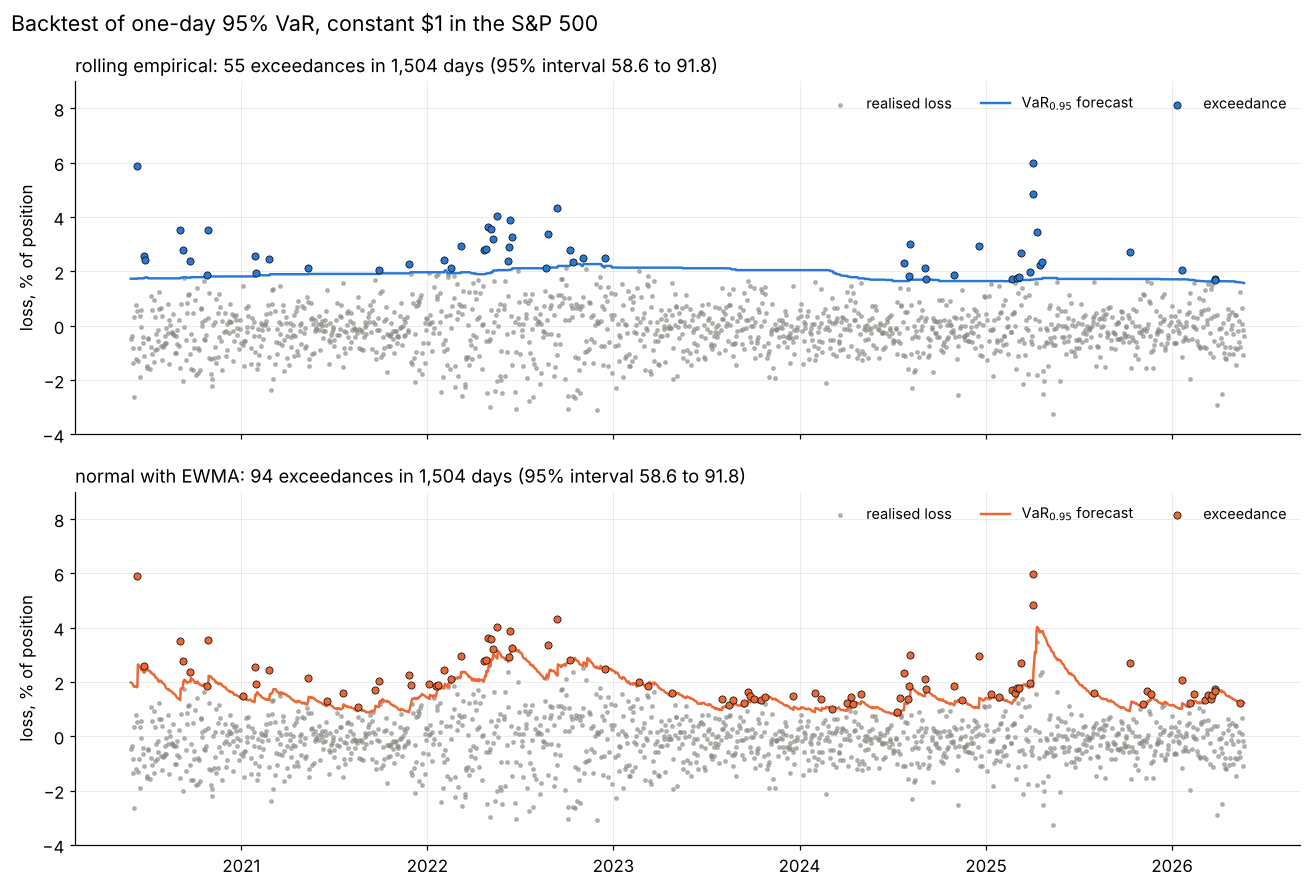

saved backtest_var_paths.png   (2 realised losses outside the plotted range -4% to 9% not shown)


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8.2), sharex=True)
for ax, v, e, col, nm, cnt in ((axes[0], var_emp, exc_emp, C_EMP, "rolling empirical", N_EMP),
                               (axes[1], var_ew, exc_ew, C_EW, "normal with EWMA", N_EW)):
    ax.scatter(eval_dates, 100 * realised, s=5, color=C_MUTE, alpha=0.55, zorder=1, label="realised loss")
    ax.plot(eval_dates, 100 * v, color=col, lw=1.6, zorder=2, label="VaR$_{0.95}$ forecast")
    ax.scatter(eval_dates[e], 100 * realised[e], s=22, color=col, edgecolor=C_INK, linewidth=0.5,
               zorder=3, label="exceedance")
    ax.set_ylim(-4, 9)
    ax.set_ylabel("loss, % of position")
    ax.set_title(f"{nm}: {cnt} exceedances in {J:,} days "
                 f"(95% interval {LO:.1f} to {HI:.1f})", loc="left", fontsize=12)
    ax.legend(loc="upper right", ncol=3, fontsize=9.5)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
n_cut = int((100 * realised > 9).sum() + (100 * realised < -4).sum())
fig.suptitle(r"Backtest of one-day 95% VaR, constant \$1 in the S&P 500", fontsize=14, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG1, bbox_inches="tight")
plt.show()
print(f"saved {FIG1}   ({n_cut} realised losses outside the plotted range -4% to 9% not shown)")

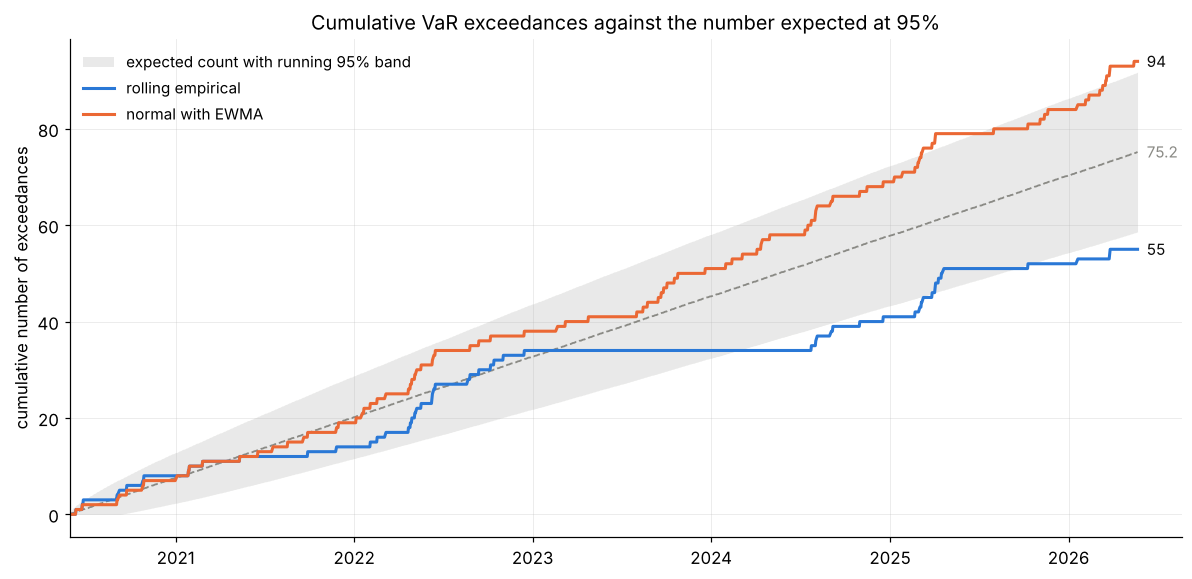

saved backtest_cumulative_exceedances.png


In [10]:
days = np.arange(1, J + 1)
exp_run = (1 - ALPHA) * days
band = Z_B * np.sqrt(days * ALPHA * (1 - ALPHA))
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.fill_between(eval_dates, np.maximum(exp_run - band, 0), exp_run + band, color=C_MUTE, alpha=0.18, lw=0,
                label="expected count with running 95% band")
ax.plot(eval_dates, exp_run, color=C_MUTE, lw=1.2, ls="--")
for e, col, nm in ((exc_emp, C_EMP, "rolling empirical"), (exc_ew, C_EW, "normal with EWMA")):
    run = np.cumsum(e)
    ax.plot(eval_dates, run, color=col, lw=2.0, label=nm)
    ax.annotate(f"{run[-1]}", xy=(eval_dates[-1], run[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=10, color=C_INK)
ax.annotate(f"{CENTRE:.1f}", xy=(eval_dates[-1], CENTRE), xytext=(6, 0), textcoords="offset points",
            va="center", fontsize=10, color=C_MUTE)
ax.set_xlim(eval_dates[0], eval_dates[-1] + pd.Timedelta(days=90))
ax.set_ylabel("cumulative number of exceedances")
ax.set_title("Cumulative VaR exceedances against the number expected at 95%")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG2, bbox_inches="tight")
plt.show()
print(f"saved {FIG2}")

---
## 10. All numbers for the written PDF

In [11]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"\n[TASK 1] N = {N:,} closes, {px.index[0].date()} -> {px.index[-1].date()}; {n_ret:,} log returns")
print(f"[WINDOW] M = {M_WIN}, J = {J:,}, first evaluation {eval_dates[0].date()}, last {eval_dates[-1].date()}")
print(f"[TASK 2] empirical: k* = {K_STAR}, exceedances {N_EMP} ({N_EMP / J:.2%}), mean VaR {var_emp.mean():.4%}")
print(f"[TASK 3] EWMA: mu0 = {MU_INIT:.6e}, sigma0 = {np.sqrt(VAR_INIT):.6f}; exceedances {N_EW} ({N_EW / J:.2%}),"
      f" mean VaR {var_ew.mean():.4%};  alt. init {N_EW_B};  mu = 0: {N_EW0}")
print(f"[TASK 4] interval [{LO:.4f}, {HI:.4f}]  (centre {CENTRE:.2f}, half-width {HALF:.4f})")
print(f"         empirical {N_EMP}: {verdict(N_EMP)}")
print(f"         EWMA      {N_EW}: {verdict(N_EW)}")

SUMMARY OF RESULTS

[TASK 1] N = 2,515 closes, 2016-05-23 -> 2026-05-22; 2,514 log returns
[WINDOW] M = 1010, J = 1,504, first evaluation 2020-05-29, last 2026-05-22
[TASK 2] empirical: k* = 960, exceedances 55 (3.66%), mean VaR 1.8830%
[TASK 3] EWMA: mu0 = 3.877131e-04, sigma0 = 0.012413; exceedances 94 (6.25%), mean VaR 1.6250%;  alt. init 94;  mu = 0: 87
[TASK 4] interval [58.6340, 91.7660]  (centre 75.20, half-width 16.5660)
         empirical 55: outside (below): reject - VaR too high, model too pessimistic
         EWMA      94: outside (above): reject - VaR too low, model too optimistic


---
## 11. Self-checks

In [12]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("N = 2,515 closes and 2,514 returns", N == 2515 and n_ret == 2514)
check("J = N - 1 - M", J == N - 1 - M_WIN)
check("k* = 960", K_STAR == 960)
# empirical VaR recomputed with a different routine (np.partition) on a few days
for j in (0, 1, 500, J - 1):
    i = M_WIN + j
    alt = np.partition(loss(xv[i - M_WIN:i]), K_STAR - 1)[K_STAR - 1]
    check(f"empirical VaR on evaluation day {j} matches np.partition", abs(alt - var_emp[j]) < 1e-15)
# the closed-form normal VaR against a direct quantile computation
mu_t, sd_t = mu_ew[123], sd_ew[123]
q_direct = loss(norm.ppf(1 - ALPHA, mu_t, sd_t))
check("normal VaR formula equals loss at the (1-alpha)-quantile of X", abs(q_direct - var_ew[123]) < 1e-15)
rng = np.random.default_rng(0)
sim = loss(rng.normal(mu_t, sd_t, 2_000_000))
check("normal VaR formula agrees with simulation", abs(np.quantile(sim, ALPHA) - var_ew[123]) < 2e-4)
check("forecast for day i uses no return from day i (first EWMA VaR depends on returns 1..M only)",
      abs(var_ew[0] - (1 - np.exp(xv[:M_WIN].mean() + xv[:M_WIN].std(ddof=1) * Z_LO))) < 1e-15)
check("interval centre and half-width", abs(CENTRE - 0.05 * J) < 1e-9 and abs(HALF - Z_B * np.sqrt(J * 0.0475)) < 1e-9)
check("exceedance counts recomputed independently",
      N_EMP == sum(loss(xv[M_WIN + j]) > var_emp[j] for j in range(J)))
check("figures written", FIG1.exists() and FIG2.exists())

for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  N = 2,515 closes and 2,514 returns
  [PASS]  J = N - 1 - M
  [PASS]  k* = 960
  [PASS]  empirical VaR on evaluation day 0 matches np.partition
  [PASS]  empirical VaR on evaluation day 1 matches np.partition
  [PASS]  empirical VaR on evaluation day 500 matches np.partition
  [PASS]  empirical VaR on evaluation day 1503 matches np.partition
  [PASS]  normal VaR formula equals loss at the (1-alpha)-quantile of X
  [PASS]  normal VaR formula agrees with simulation
  [PASS]  forecast for day i uses no return from day i (first EWMA VaR depends on returns 1..M only)
  [PASS]  interval centre and half-width
  [PASS]  exceedance counts recomputed independently
  [PASS]  figures written

ALL CHECKS PASSED
